# 🧩 Notebook 5 — Step Growth & Gelation
| | |
|---|---|
| ⏱ Time | ~45 min |
| 🧭 Type | sequential event sampling (no time), then **dynamic Monte Carlo** (book Ch. 4, Case Study 4.1) |
| 🎯 You will learn | pick *two* molecules and join them · Carothers & Flory checks · a first taste of **time** (Gillespie) · find the **gel point** |
| 📖 Book | Sec. 4.1–4.4 · Algorithms for AA + BB, Gillespie step growth, AB + A₃, and gelation with a disjoint set |

Chain growth (Notebooks 2–4) adds monomers one by one. In **step growth**, *any* two molecules with matching ends (A + B) can link. Theory: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(5)

## 1 · AA + BB: "pick two, check the ends, join"
Each molecule is a small list: `[length, end1, end2]`. A diacid (AA) is `[1, "A", "A"]`, a diol (BB) is `[1, "B", "B"]`.

In [2]:
N0 = 20_000
pool = []
for k in range(N0):
    pool.append([1, "A", "A"])
    pool.append([1, "B", "B"])

print(len(pool), "molecules")

40000 molecules


One reaction attempt:
1. pick two **different** molecules at random,
2. pick one end of each (end 1 or end 2),
3. if one end is A and the other B, **link** them. The new molecule keeps the two *other* ends.

If `end_i` is 1, the other end is 2, and vice versa: that's `3 − end_i`.

In [3]:
def try_reaction(pool):
    i = random.randrange(len(pool))
    j = random.randrange(len(pool))
    end_i = random.randint(1, 2)
    end_j = random.randint(1, 2)
    if i == j or pool[i][end_i] == pool[j][end_j]:
        return False                                  # no reaction this time
    pool[i] = [pool[i][0] + pool[j][0], pool[i][3 - end_i], pool[j][3 - end_j]]
    pool[j] = pool[-1]                                # remove molecule j quickly
    pool.pop()
    return True

Now react until the **conversion** of A groups, `p = 1 − (A groups left)/(A groups at start)`, reaches 0.95. Each successful reaction uses up one A group. After each one we record `p` and the number-average chain length `Nn` (monomers at start ÷ molecules now).

In [4]:
nuA0 = 2 * N0          # A groups at the start
nuA = nuA0
p_list, Nn_list = [], []

while 1 - nuA / nuA0 < 0.95:
    if try_reaction(pool):
        nuA -= 1
        p_list.append(1 - nuA / nuA0)
        Nn_list.append(2 * N0 / len(pool))

Take a snapshot of the chain lengths at p = 0.95, then continue to 0.98:

In [5]:
snapshot = []
for molecule in pool:
    snapshot.append(molecule[0])

while 1 - nuA / nuA0 < 0.98:
    if try_reaction(pool):
        nuA -= 1
        p_list.append(1 - nuA / nuA0)
        Nn_list.append(2 * N0 / len(pool))

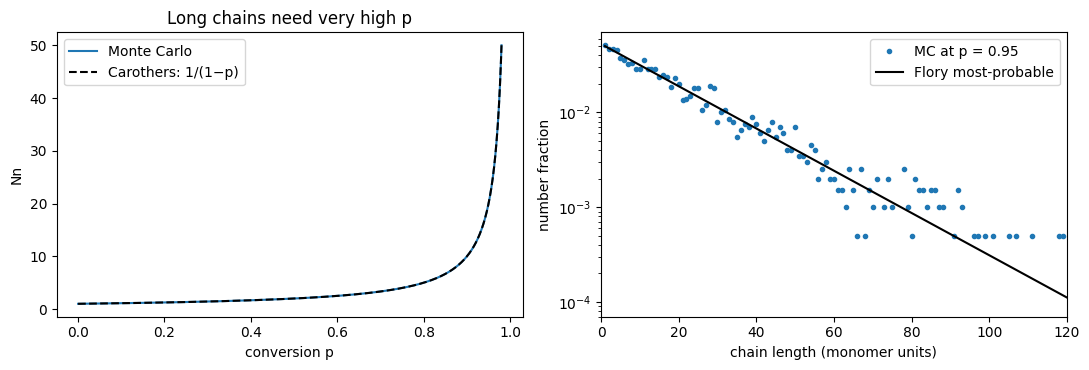

In [6]:
#@title Plot Nn vs. conversion, and the chain length distribution
p = np.array(p_list); Nn = np.array(Nn_list)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(p, Nn, label="Monte Carlo"); ax[0].plot(p, 1/(1-p), "k--", label="Carothers: 1/(1−p)")
ax[0].set_xlabel("conversion p"); ax[0].set_ylabel("Nn"); ax[0].legend(); ax[0].set_title("Long chains need very high p")
cnt = np.bincount(snapshot)[1:]; nn = np.arange(1, len(cnt) + 1)
ax[1].semilogy(nn, cnt/cnt.sum(), ".", label="MC at p = 0.95"); ax[1].semilogy(nn, 0.05*0.95**(nn-1), "k-", label="Flory most-probable")
ax[1].set_xlim(0, 120); ax[1].set_xlabel("chain length (monomer units)"); ax[1].set_ylabel("number fraction"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2 · Adding a clock: Gillespie's method for step growth (dynamic Monte Carlo)
So far we know *what* happened, not *when*. Trick #4 from Notebook 1 adds the time:
- the propensity (total rate) is `a = k_MC · n_A · n_B`, with `k_MC = k / (N_A·V)`
- the waiting time is `τ = ln(1/Rnd) / a`

Here every molecule has one A and one B end (AB monomers), so any two molecules can link. A helper merges two random molecules:

In [7]:
def merge_two(sizes):
    i = random.randrange(len(sizes))
    j = random.randrange(len(sizes))
    while j == i:                       # make sure they are different
        j = random.randrange(len(sizes))
    sizes[i] += sizes[j]
    sizes[j] = sizes[-1]                # remove molecule j quickly
    sizes.pop()

In [8]:
NA = 6.022e23          # Avogadro's number

In [9]:
def gillespie_step_growth(N0, k, A0):
    V = N0 / (A0 * NA)                  # volume holding N0 A groups
    kMC = k / (NA * V)
    nA, t, sizes = N0, 0.0, [1] * N0
    times, conversions = [0.0], [0.0]
    while nA > 1:
        a = kMC * nA * nA               # propensity (n_A = n_B)
        t += np.log(1 / random.random()) / a
        merge_two(sizes)
        nA -= 1
        times.append(t)
        conversions.append(1 - nA / N0)
    return np.array(times), np.array(conversions)

For equal amounts of A and B, theory says `1/(1 − p) = 1 + k[A]₀t`: a straight line. Try three system sizes:

In [10]:
k, A0 = 1e-2, 1.0                      # L/(mol·s), mol/L
runs = {}
for N0 in [100, 1_000, 20_000]:
    runs[N0] = gillespie_step_growth(N0, k, A0)

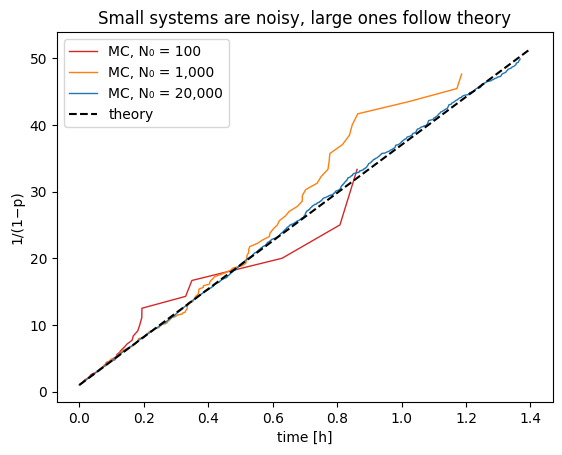

In [11]:
#@title Plot 1/(1−p) against time
for N0, c in [(100, "tab:red"), (1_000, "tab:orange"), (20_000, "tab:blue")]:
    t, p = runs[N0]; m = p < 0.98
    plt.plot(t[m]/3600, 1/(1-p[m]), c=c, lw=1, label=f"MC, N₀ = {N0:,}")
tt = np.linspace(0, 1.4, 50); plt.plot(tt, 1 + k*A0*tt*3600, "k--", label="theory")
plt.xlabel("time [h]"); plt.ylabel("1/(1−p)"); plt.legend(); plt.title("Small systems are noisy, large ones follow theory"); plt.show()

## 3 · Branching monomers: AB + A₃ (star-like polymers)
Add a few A₃ "core" molecules to an AB monomer. For each molecule we keep: its number of free A groups, whether it still has its B group, and whether it contains a core.

`[1] * 3 + [3] * 2` makes the list `[1, 1, 1, 3, 3]`.

In [12]:
def start_ab_a3(n_AB, n_A3):
    free_A = [1] * n_AB + [3] * n_A3
    has_core = [False] * n_AB + [True] * n_A3
    poolA = list(range(n_AB + n_A3))     # molecules with a free A group
    poolB = list(range(n_AB))            # molecules with a free B group
    return free_A, has_core, poolA, poolB

Linking molecule `j`'s B group to one of molecule `i`'s A groups merges `j` into `i`:

In [13]:
def link(i, j, free_A, has_core, poolA, poolB):
    free_A[i] = free_A[i] - 1 + free_A[j]
    has_core[i] = has_core[i] or has_core[j]
    poolB.remove(j)                      # j's B group is used
    if j in poolA:
        poolA.remove(j)                  # j is now part of i
    if free_A[i] == 0:
        poolA.remove(i)

The rules (book: *Sequential Event Sampling for AB + A₃*): the two molecules must be different, and not both contain a core. We stop when no B groups are left, or when no valid pair can be found.

In [14]:
def choose_pair(poolA, poolB, has_core):
    for attempt in range(1000):
        i = random.choice(poolA)
        j = random.choice(poolB)
        if i != j and not (has_core[i] and has_core[j]):
            return i, j
    return None                          # no valid pair could be found

In [15]:
def ab_a3(n_AB, n_A3):
    free_A, has_core, poolA, poolB = start_ab_a3(n_AB, n_A3)
    N0 = n_AB + n_A3
    molecules = N0
    Nn_list = []
    while len(poolB) > 0:
        pair = choose_pair(poolA, poolB, has_core)
        if pair is None:
            break
        link(pair[0], pair[1], free_A, has_core, poolA, poolB)
        molecules -= 1
        Nn_list.append(N0 / molecules)
    return np.array(Nn_list)

Prediction: once every B group has reacted, every molecule is attached to a core, so `Nn` stops at `N₀ / n_A3`.

In [16]:
star_runs = {}
for n_A3 in [0, 15, 30, 60]:
    star_runs[n_A3] = ab_a3(3000, n_A3)
    print(f"n_A3 = {n_A3:2d}:  final Nn = {star_runs[n_A3][-1]:.0f}")

n_A3 =  0:  final Nn = 3000
n_A3 = 15:  final Nn = 201
n_A3 = 30:  final Nn = 101
n_A3 = 60:  final Nn = 51


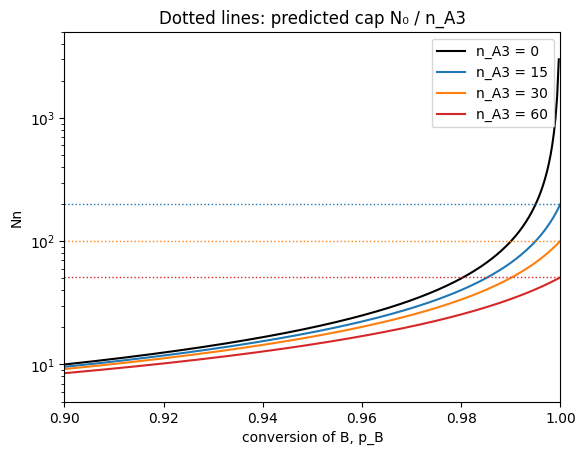

In [17]:
#@title Plot Nn against the conversion of B
for n_A3, c in [(0, "k"), (15, "tab:blue"), (30, "tab:orange"), (60, "tab:red")]:
    Nn = star_runs[n_A3]; pB = np.arange(1, len(Nn) + 1) / 3000
    plt.plot(pB, Nn, c=c, label=f"n_A3 = {n_A3}")
    if n_A3: plt.axhline((3000 + n_A3)/n_A3, c=c, ls=":", lw=1)
plt.yscale("log"); plt.xlim(0.9, 1.0); plt.ylim(5, 5000); plt.xlabel("conversion of B, p_B"); plt.ylabel("Nn")
plt.legend(); plt.title("Dotted lines: predicted cap N₀ / n_A3"); plt.show()

## 4 · Gelation: finding the giant molecule 🕸️
With A₂ + B₃ (e.g. a diacid and a triol) a **network** forms. At the *gel point*, one giant molecule suddenly spans the system.

Keeping full molecule lists would be slow. The book uses a **disjoint set** (DSU): every monomer points to a `parent`; following the parents leads to the molecule's **root**. Two monomers belong to the same molecule if they have the same root.

In [18]:
def find_root(parent, x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]      # shortcut: skip a level
        x = parent[x]
    return x

Joining two molecules = pointing one root to the other. We keep `size[root]`, the number of monomers in each molecule, and attach the smaller molecule to the larger one:

In [19]:
def join(parent, size, a, b):
    ra = find_root(parent, a)
    rb = find_root(parent, b)
    if ra != rb:
        if size[ra] < size[rb]:
            ra, rb = rb, ra                # make ra the larger one
        parent[rb] = ra
        size[ra] += size[rb]
    return size[ra]                        # size of the merged molecule

The reacting groups: one list of free A groups and one of free B groups. Each entry is the number of the monomer the group belongs to, so an A₂ monomer appears twice and a B₃ monomer three times.

In [20]:
def make_groups(n_A2, n_B3):
    freeA, freeB = [], []
    for m in range(n_A2):
        freeA += [m, m]                    # two A groups
    for m in range(n_A2, n_A2 + n_B3):
        freeB += [m, m, m]                 # three B groups
    return freeA, freeB

To pick and remove a random group, we reuse the pool trick from Notebook 4:

In [21]:
def take_random(pool):
    k = random.randrange(len(pool))
    chosen = pool[k]
    pool[k] = pool[-1]
    pool.pop()
    return chosen

React random A–B pairs until one kind runs out. After each bond, record the conversion of A and the size of the largest molecule (as a fraction of all monomers).

In [22]:
def gelation(n_A2, n_B3):
    freeA, freeB = make_groups(n_A2, n_B3)
    total = n_A2 + n_B3
    parent, size = list(range(total)), [1] * total
    totA, largest, pA, L = len(freeA), 1, [], []
    while len(freeA) > 0 and len(freeB) > 0:
        a, b = take_random(freeA), take_random(freeB)
        largest = max(largest, join(parent, size, a, b))
        pA.append(1 - len(freeA) / totA)
        L.append(largest / total)
    return np.array(pA), np.array(L)

Three system sizes, with equal numbers of A and B groups (A₂ : B₃ = 3 : 2):

In [23]:
gel_runs = {}
for scale in [50, 500, 5000]:
    gel_runs[scale] = gelation(3 * scale, 2 * scale)

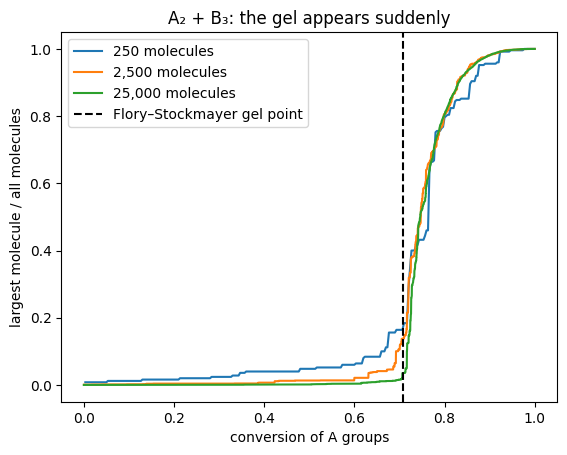

In [24]:
#@title Plot the largest molecule against conversion
for scale in gel_runs:
    pA, L = gel_runs[scale]; plt.plot(pA, L, label=f"{5*scale:,} molecules")
plt.axvline(1/np.sqrt(2), c="k", ls="--", label="Flory–Stockmayer gel point")
plt.xlabel("conversion of A groups"); plt.ylabel("largest molecule / all molecules")
plt.legend(); plt.title("A₂ + B₃: the gel appears suddenly"); plt.show()

## ✅ Recap
- Step growth = **pick two, check compatibility, merge**.
- Gillespie adds real **time** with one extra line.
- Simple bookkeeping (pools, parents) keeps big simulations fast.
- Bigger systems give sharper, more theory-like transitions.

### 🧪 Try it yourself
1. Unbalance AA/BB (e.g. 20,000 AA and 19,000 BB). What is the largest Nn you can reach?
2. Try A₂ + B₄ (change `make_groups`). Where should the gel point move? (α_c = 1/√((f_A−1)(f_B−1)))
3. In the Gillespie cell, double `k`. What changes and what doesn't?

➡️ **Next: Notebook 6 — Dynamic Monte Carlo: Gillespie's method for free-radical polymerization**